### Step1. Loading all nessesory Packages and Modules and Liberaries 

In [ ]:
!pip install tensorflow

In [ ]:
!pip install keras

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

### Step2. Loading the Dataset

In [4]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [6]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0,

### Step3. Getting to Know the Data

In [8]:
X.shape

(569, 30)

In [10]:
y.shape

(569,)

In [12]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [14]:
pd.Series(y).value_counts()

1    357
0    212
Name: count, dtype: int64

### Splitting the data 

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,test_size=0.40,random_state=42, stratify = y )

In [18]:
X_train.shape        # training data shape

(341, 30)

In [20]:
X_test.shape        # testing data shape 

(228, 30)

In [22]:
print(pd.Series(y_train).value_counts())
print(pd.Series(y_test).value_counts())

1    214
0    127
Name: count, dtype: int64
1    143
0     85
Name: count, dtype: int64


In [24]:
X_train.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000,...,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000
mean,14.066660,19.301906,91.511114,647.823754,0.095785,0.102525,0.088216,0.047773,0.180738,0.062732,...,16.203669,25.722111,106.868094,872.094721,0.132364,0.255823,0.279808,0.113985,0.292525,0.084265
std,3.462553,4.564336,23.860522,333.929733,0.013229,0.053285,0.081405,0.038037,0.028631,0.007238,...,4.790035,6.365029,33.334622,548.758626,0.022706,0.165893,0.227361,0.067727,0.064909,0.019082
min,6.981000,9.710000,43.790000,143.500000,0.062510,0.019380,0.000000,0.000000,0.116700,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.081250,0.034320,0.000000,0.000000,0.160300,0.055210
25%,11.670000,15.820000,74.720000,419.800000,0.085970,0.061590,0.026880,0.019670,0.160900,0.057460,...,13.060000,20.980000,83.990000,518.100000,0.114800,0.137900,0.103900,0.063430,0.247300,0.071130
50%,13.270000,18.830000,85.890000,542.900000,0.094630,0.087510,0.058920,0.032630,0.178200,0.061290,...,14.850000,25.580000,97.670000,680.600000,0.131400,0.217000,0.228200,0.096780,0.283700,0.079570
75%,15.780000,21.980000,105.700000,782.600000,0.104600,0.129600,0.132400,0.074150,0.195900,0.066500,...,18.810000,29.410000,126.300000,1095.000000,0.146000,0.339100,0.392000,0.173200,0.321500,0.092180
max,25.220000,39.280000,171.500000,1878.000000,0.139800,0.345400,0.426400,0.184500,0.304000,0.095750,...,31.010000,49.540000,211.700000,3143.000000,0.218400,1.058000,1.252000,0.291000,0.577400,0.207500


### Standardization

In [26]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [28]:
df1 = pd.DataFrame(X_train_scaled , columns = X_train.columns)

In [30]:
df1.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,3.410000e+02,3.410000e+02,3.410000e+02,3.410000e+02,3.410000e+02,3.410000e+02,3.410000e+02,3.410000e+02,3.410000e+02,3.410000e+02,...,3.410000e+02,3.410000e+02,3.410000e+02,3.410000e+02,3.410000e+02,3.410000e+02,3.410000e+02,3.410000e+02,3.410000e+02,3.410000e+02
mean,-1.604451e-15,1.765938e-15,1.010596e-15,8.699460e-16,-1.513940e-15,-4.063221e-16,-9.272479e-16,-6.016693e-16,3.771502e-15,-3.495412e-15,...,-3.281832e-16,-5.120700e-15,-4.024151e-15,-2.500444e-16,3.844432e-15,-5.105072e-16,7.006451e-16,4.610193e-16,-7.345053e-16,-1.093944e-15
std,1.001470e+00,1.001470e+00,1.001470e+00,1.001470e+00,1.001470e+00,1.001470e+00,1.001470e+00,1.001470e+00,1.001470e+00,1.001470e+00,...,1.001470e+00,1.001470e+00,1.001470e+00,1.001470e+00,1.001470e+00,1.001470e+00,1.001470e+00,1.001470e+00,1.001470e+00,1.001470e+00
min,-2.049376e+00,-2.104578e+00,-2.002942e+00,-1.512488e+00,-2.518965e+00,-1.562679e+00,-1.085256e+00,-1.257807e+00,-2.239962e+00,-1.767276e+00,...,-1.729805e+00,-2.155881e+00,-1.696166e+00,-1.253564e+00,-2.254471e+00,-1.337180e+00,-1.232484e+00,-1.685487e+00,-2.040055e+00,-1.524863e+00
25%,-6.931827e-01,-7.639716e-01,-7.047536e-01,-6.838530e-01,-7.430243e-01,-7.693593e-01,-7.545701e-01,-7.399226e-01,-6.939093e-01,-7.294946e-01,...,-6.572579e-01,-7.461207e-01,-6.873248e-01,-6.460307e-01,-7.746911e-01,-7.118824e-01,-7.748312e-01,-7.475554e-01,-6.977577e-01,-6.893601e-01
50%,-2.304169e-01,-1.035418e-01,-2.359284e-01,-3.146708e-01,-8.745549e-02,-2.822037e-01,-3.604042e-01,-3.987033e-01,-8.877994e-02,-1.995341e-01,...,-2.830163e-01,-2.235972e-02,-2.763376e-01,-3.494726e-01,-4.251965e-02,-2.343673e-01,-2.273213e-01,-2.544132e-01,-1.361527e-01,-2.464176e-01
75%,4.955471e-01,5.876056e-01,5.955333e-01,4.041997e-01,6.672813e-01,5.088603e-01,5.435690e-01,6.944624e-01,5.303409e-01,5.213783e-01,...,5.449149e-01,5.802500e-01,5.837913e-01,4.067960e-01,6.014384e-01,5.027325e-01,4.941761e-01,8.755997e-01,4.470525e-01,4.153721e-01
max,3.225866e+00,4.383431e+00,3.357279e+00,3.689351e+00,3.331949e+00,4.564731e+00,4.160446e+00,3.599829e+00,4.311525e+00,4.568727e+00,...,3.095612e+00,3.747491e+00,3.149457e+00,4.144340e+00,3.794765e+00,4.842626e+00,4.282258e+00,2.617493e+00,4.395259e+00,6.467520e+00


### Creating A Artificial Neural Network 

In [72]:
model = Sequential()     # Empty network 

model.add(Dense(                      # first Input layer with 30 neurons and hidden layer as 16 neurons 
    units=30,
    input_shape=(30,)
))

C:\Users\Om Computers\AppData\Local\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [74]:
model.add(Dense(
    units=16,
    activation='relu'
))

In [76]:
# output layer 
model.add(Dense(
    units=1,
    activation='sigmoid'
))

In [78]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                      │ (None, 30)                  │             930 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 16)                  │             496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,443 (5.64 KB)

 Trainable params: 1,443 (5.64 KB)

 Non-trainable params: 0 (0.00 B)

In [80]:
model.compile(                   # optimizer - helps to update the weights in process of forward and backward propagation
    loss='binary_crossentropy',         # Binary_crossentroypy - Because the target is Binary classification
    metrics=['accuracy']          
)

In [82]:
history = model.fit(
    X_train_scaled,    # features 
    y_train,    # target 
    epochs=30,
    batch_size = 20,
    validation_split = 0.3
)

Epoch 1/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.8655 - loss: 0.4196 - val_accuracy: 0.9612 - val_loss: 0.2742
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9244 - loss: 0.2868 - val_accuracy: 0.9709 - val_loss: 0.1951
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9454 - loss: 0.2164 - val_accuracy: 0.9709 - val_loss: 0.1499
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9622 - loss: 0.1741 - val_accuracy: 0.9806 - val_loss: 0.1233
Epoch 5/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9664 - loss: 0.1467 - val_accuracy: 0.9806 - val_loss: 0.1042
Epoch 6/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9664 - loss: 0.1271 - val_accuracy: 0.9806 - val_loss: 0.0902
Epoch 7/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9664 - loss: 0.1136 - val_accuracy: 0.9806 - val_loss: 0.0813
Epoch 8/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9748 - loss: 0.1032 - val_accuracy: 0.9806 - v

In [84]:
loss, accuracy = model.evaluate(X_test_scaled, y_test)

print("Loss:", loss)
print("Accuracy:", accuracy)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9868 - loss: 0.0441 
Loss: 0.044070079922676086
Accuracy: 0.9868420958518982


In [86]:
predictions = model.predict(X_test_scaled)

predictions[:10]

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


array([[9.6341938e-01],
       [5.1194835e-01],
       [9.9897480e-01],
       [9.9816924e-01],
       [9.9919420e-01],
       [5.2447650e-03],
       [9.9948257e-01],
       [1.1324475e-07],
       [7.8076792e-01],
       [8.2322316e-05]], dtype=float32)

In [88]:
predicted_class = (predictions > 0.5).astype(int)

predicted_class[:10]

array([[1],
       [1],
       [1],
       [1],
       [1],
       [0],
       [1],
       [0],
       [1],
       [0]])

In [90]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, predicted_class)
cm

array([[ 84,   1],
       [  2, 141]], dtype=int64)

In [92]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    predicted_class
))

              precision    recall  f1-score   support

           0       0.98      0.99      0.98        85
           1       0.99      0.99      0.99       143

    accuracy                           0.99       228
   macro avg       0.98      0.99      0.99       228
weighted avg       0.99      0.99      0.99       228



In [94]:
from sklearn.metrics import accuracy_score

accuracy_score(
    y_test,
    predicted_class
)

0.9868421052631579

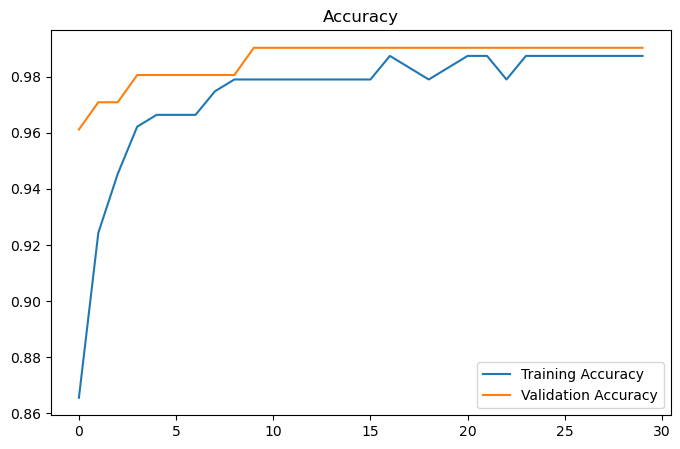

In [98]:
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.legend()

plt.title("Accuracy")

plt.show()

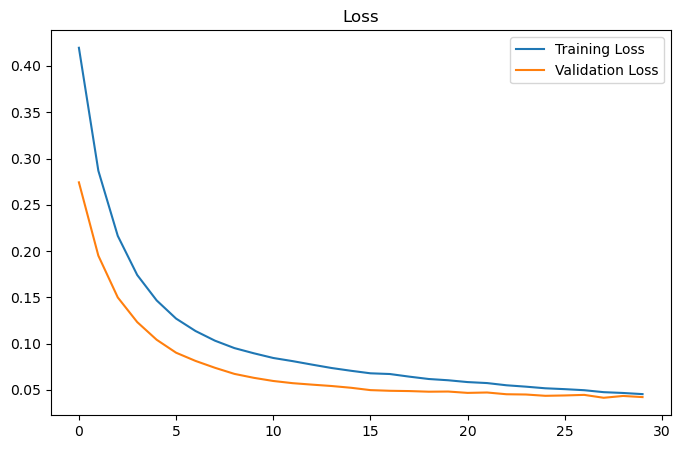

In [100]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.legend()

plt.title("Loss")

plt.show()

In [106]:
sample = X.iloc[[27]]

sample_scaled = scaler.transform(sample)

prediction = model.predict(sample_scaled)

print(prediction)

if prediction > 0.5:
    print("Benign")
else:
    print("Malignant")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
[[9.433574e-06]]
Malignant
